#Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

##Singular Value Decomposition
Lets load an image and try to do it's SVD.

Please note the way to access an image from your Google drive. Change the code accordingly (and load an image in your Google drive) to access to your own image!

Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image

In [ ]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix). What will happen if its not gray-scale?

# **If the image would not be gray-scale then it would be 3-dimentional istead of 2-dimentional and we would not make a 2D matrix.**

Mark how we have used the command $matrix$ to generate a matrix from the image!

In [ ]:
img = Image.open("/content/drive/My Drive/DSC_0716a.JPG")
imggray = img.convert('L')

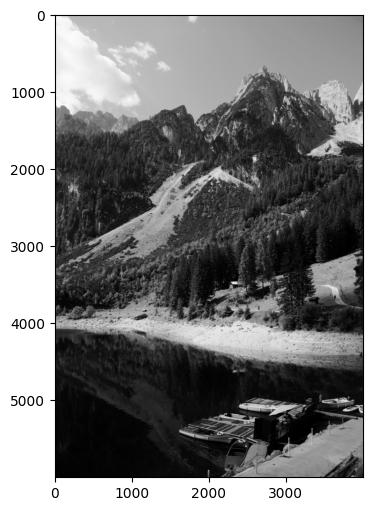

In [ ]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
imgmat = np.matrix(imgmat)
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')

###SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

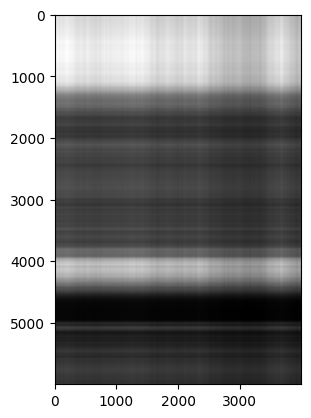

In [ ]:
U, sigma, V = np.linalg.svd(imgmat)
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstimg, cmap='gray');


Now lets check how does the sigma vector look like.

What do you observe? How many vecotrs can we use to get a decent reconstruction of the image?
What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?

# **The first few values are large compared to others, so majority of the imagne's is in first few vectors. To get a decent reconstruction we need several dozen vectors but it depends on the size of the image. If we omit the first 1-2 vectors we loss the low-frequency data that holds the brightness and gradients of the image.**

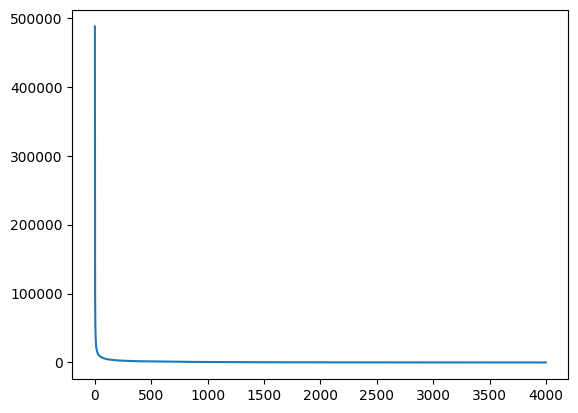

In [ ]:
U.shape
sigma.shape
plt.plot(sigma)

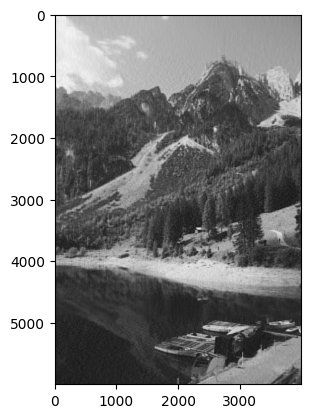

In [ ]:
i = 90
j = 0
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');

# **Sentinel 2 image with different terrains**

In [ ]:
img2 = Image.open("/content/drive/My Drive/2026-10-11-00_00_2026-10-11-23_59_Sentinel-2_L2A_True_color(1).jpg")
imggray = img2.convert('L')

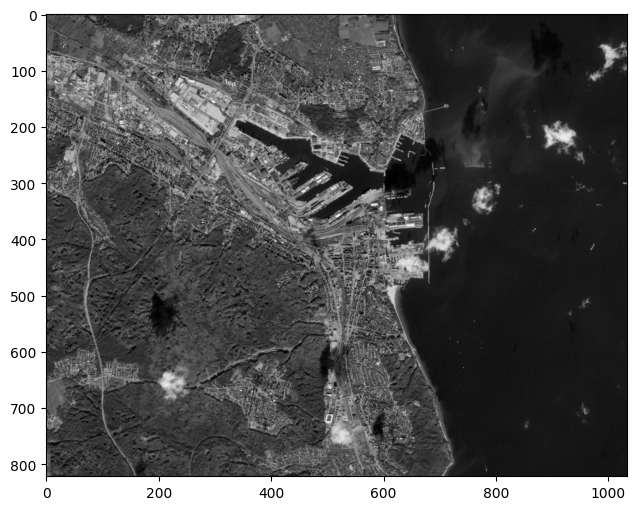

In [ ]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
imgmat = np.matrix(imgmat)
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')

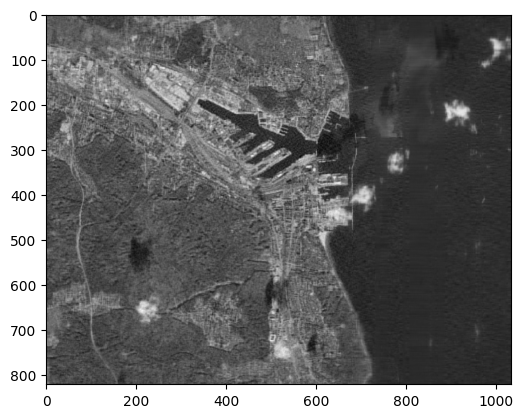

In [ ]:
i = 90
j = 0
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');

# **Observations**


The singular values drop off exponentially. The first few values carry the bulk of the image's energy, later values represent finer textures and high-frequency details.

The largest singular values contain the essential low-frequency information.
By skiping them, we throw away the foundation of the image.


For satellite image of different terrains the terrains differently impact how many values are required to capture them without degradation. Ocean is smooth and low texture so it needs the lowest value, forests are dense and repetitive textures so we need higher value, for urban the textures are sharp lines so it needs the highest value.